# Hierarchical Cluster Markov Chain Model for EcoBici

Two-level clustering hierarchy:

```
Macro Cluster (e.g. alcaldía)  ←  Level 0 ("big")
  └── Micro Cluster (e.g. K-Means within each macro)  ←  Level 1 ("small")
        └── Station  ←  leaves
```

For every **micro cluster** `(M, s)` we compute:

| Flow type | Description |
|---|---|
| **Internal** | station → station within the same micro cluster |
| **Sibling outflow / inflow** | to / from another micro cluster **in the same macro** cluster |
| **External outflow / inflow** | to / from a **different macro** cluster |

For every **macro cluster** `M` we additionally get:

| Flow type | Description |
|---|---|
| **Internal** | trip stays inside macro cluster `M` (any micro → any micro) |
| **Outflow / Inflow** | to / from another macro cluster |

Both clustering levels are independently configurable.

In [84]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
import folium
from sklearn.cluster import KMeans

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
                                         "#e87ba4", "#008300", "#6250d6", "#e34948"]),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "lines.linewidth": 2,
    "lines.markersize": 5,
})

## 1. Load and clean data

In [85]:
def fix_station_id(station):
    """Normalise station IDs: strip whitespace, handle 'NNN-M' duplicates, return int."""
    if pd.isna(station):
        return None
    station = str(station).strip()
    if station == "":
        return None
    if "-" in station:
        station = station.split("-")[0]
    return int(float(station))


# ── Stations ──────────────────────────────────────────────────────────
stations = pd.read_csv("data/estaciones_ecobici.csv", encoding="utf-8-sig")
stations["num_cicloe"] = stations["num_cicloe"].apply(fix_station_id)
stations = stations.dropna(subset=["num_cicloe", "latitud", "longitud"])
stations["num_cicloe"] = stations["num_cicloe"].astype(int)
stations = stations.drop_duplicates(subset="num_cicloe").set_index("num_cicloe")

# ── Trips ─────────────────────────────────────────────────────────────
trips = pd.read_csv("data/viajes_ecobici_092026.csv")
trips["Ciclo_Estacion_Retiro"] = trips["Ciclo_Estacion_Retiro"].apply(fix_station_id)
trips["Ciclo_EstacionArribo"] = trips["Ciclo_EstacionArribo"].apply(fix_station_id)
trips = trips.dropna(subset=["Ciclo_Estacion_Retiro", "Ciclo_EstacionArribo"])
trips["Ciclo_Estacion_Retiro"] = trips["Ciclo_Estacion_Retiro"].astype(int)
trips["Ciclo_EstacionArribo"] = trips["Ciclo_EstacionArribo"].astype(int)

print(f"Stations: {len(stations)}  |  Trips: {len(trips):,}")
trips.head(3)

Stations: 677  |  Trips: 1,498,934


,Genero_Usuario,Edad_Usuario,Bici,Ciclo_Estacion_Retiro,Fecha_Retiro,Hora_Retiro,Ciclo_EstacionArribo,Fecha_Arribo,Hora_Arribo
0,M,30.0,6583322,28,31/08/2026,23:54:59,258,01/09/2026,00:00:03
1,F,33.0,4139655,30,31/08/2026,23:24:43,530,01/09/2026,00:00:04
2,O,32.0,6378079,139,31/08/2026,23:46:59,559,01/09/2026,00:00:35


## 2. Clustering strategies (building blocks)

Each strategy is a function `(stations_df) → pd.Series[station_id → label]`.  
You mix-and-match them freely: one for the **macro** level, one for the **micro** level.

In [86]:
# ── Strategy: K-Means on (lat, lon) ───────────────────────────────────
def cluster_by_kmeans(stations_df: pd.DataFrame, k: int = 8, random_state: int = 42) -> pd.Series:
    """Cluster stations into k groups using K-Means on geographic coordinates."""
    coords = stations_df[["latitud", "longitud"]].values
    labels = KMeans(n_clusters=k, random_state=random_state, n_init=10).fit_predict(coords)
    return pd.Series(labels, index=stations_df.index, name="cluster")


# ── Strategy: one cluster per alcaldía ─────────────────────────────────
def cluster_by_alcaldia(stations_df: pd.DataFrame) -> pd.Series:
    """One cluster per alcaldía. Returns integer codes."""
    codes, uniques = pd.factorize(stations_df["alcaldia"])
    print("Alcaldía → code:", dict(zip(uniques, range(len(uniques)))))
    return pd.Series(codes, index=stations_df.index, name="cluster")


# ── Strategy: one cluster per colonia ──────────────────────────────────
def cluster_by_colonia(stations_df: pd.DataFrame) -> pd.Series:
    """One cluster per colonia (neighbourhood)."""
    codes, _ = pd.factorize(stations_df["colonia"])
    return pd.Series(codes, index=stations_df.index, name="cluster")


# ── Strategy: manual dict ─────────────────────────────────────────────
def cluster_by_manual(stations_df: pd.DataFrame, mapping: dict) -> pd.Series:
    """Assign clusters from {station_id: label}. Unknown stations get label -1."""
    return pd.Series(
        [mapping.get(sid, -1) for sid in stations_df.index],
        index=stations_df.index, name="cluster",
    )


# ── Strategy: single cluster (puts everything in one group) ───────────
def cluster_all_together(stations_df: pd.DataFrame) -> pd.Series:
    """Assign all stations to cluster 0 (useful as a no-op macro grouping)."""
    return pd.Series(0, index=stations_df.index, name="cluster")

## 3. Build hierarchical labels

We apply two clustering functions sequentially:
1. **Macro** — applied to ALL stations → assigns a `macro` label
2. **Micro** — applied **independently within each macro cluster** → assigns a `micro` label

The result is that each station gets a composite key `(macro, micro)`.

In [87]:
def build_hierarchy(
    stations_df: pd.DataFrame,
    macro_fn,
    micro_fn,
) -> pd.DataFrame:
    """
    Apply two-level clustering to stations.

    Parameters
    ----------
    stations_df : DataFrame with 'latitud', 'longitud', 'alcaldia', etc.  Index = station_id.
    macro_fn    : callable(stations_df) → Series[station_id → macro_label]
    micro_fn    : callable(stations_df) → Series[station_id → micro_label]
                  This is called ONCE PER MACRO CLUSTER on the subset of stations
                  belonging to that macro cluster.

    Returns
    -------
    The input DataFrame with two new columns: 'macro' and 'micro'.
    """
    df = stations_df.copy()
    df["macro"] = macro_fn(df)

    # Apply micro clustering within each macro cluster independently
    micro_labels = pd.Series(index=df.index, dtype=int, name="micro")
    for macro_id in sorted(df["macro"].unique()):
        mask = df["macro"] == macro_id
        subset = df.loc[mask]
        if len(subset) <= 1:
            micro_labels.loc[mask] = 0
        else:
            micro_labels.loc[mask] = micro_fn(subset).values
    df["micro"] = micro_labels
    return df

In [88]:
# =====================================================================
# ◆  CONFIGURATION — change these two lines to swap strategies         ◆
# =====================================================================

# Macro level: by alcaldía  (try: cluster_by_kmeans with k=5, cluster_all_together, ...)
MACRO_FN = lambda df: cluster_by_alcaldia(df)

# Micro level: K-Means k=10 within each macro  (try: cluster_by_colonia, k=5, ...)
MICRO_K  = 10
MICRO_FN = lambda df: cluster_by_kmeans(df, k=min(MICRO_K, len(df)))

# =====================================================================

stations = build_hierarchy(stations, macro_fn=MACRO_FN, micro_fn=MICRO_FN)

n_macro = stations["macro"].nunique()
n_micro_total = stations.groupby("macro")["micro"].nunique().sum()
print(f"Macro clusters: {n_macro}")
print(f"Total micro clusters: {n_micro_total}")
print()
print(stations.groupby("macro")["micro"].nunique().rename("n_micro_clusters"))
print()
stations[["alcaldia", "macro", "micro"]].head(10)

Alcaldía → code: {'Benito Juarez': 0, 'Alvaro Obregon': 1, 'Miguel Hidalgo': 2, 'Cuauhtemoc': 3, 'Azcapotzalco': 4, 'Coyoacan': 5}
Macro clusters: 6
Total micro clusters: 60

macro
0    10
1    10
2    10
3    10
4    10
5    10
Name: n_micro_clusters, dtype: int64



,alcaldia,macro,micro
num_cicloe,,,
423,Benito Juarez,0,1.0
437,Benito Juarez,0,1.0
438,Benito Juarez,0,1.0
439,Benito Juarez,0,1.0
440,Benito Juarez,0,1.0
415,Benito Juarez,0,1.0
420,Benito Juarez,0,7.0
421,Benito Juarez,0,7.0
422,Benito Juarez,0,7.0


## 4. Flat `ClusterMarkovModel` (reusable building block)

This is the same single-level model from before — we'll compose it at both levels.

In [89]:
class ClusterMarkovModel:
    """
    Single-level Markov-chain model for bicycle flows within and between
    clusters.  Used as a building block by the hierarchical model.

    Parameters
    ----------
    trips_df    : Must have 'origin' and 'dest' columns (station ids).
    stations_df : Must have a 'cluster' column; index = station_id.
    """

    def __init__(self, trips_df: pd.DataFrame, stations_df: pd.DataFrame,
                 origin_col: str = "origin", dest_col: str = "dest"):
        self.stations = stations_df.copy()
        self.cluster_labels = sorted(self.stations["cluster"].unique())
        self._s2c = self.stations["cluster"].to_dict()

        self.trips = trips_df[[origin_col, dest_col]].copy()
        self.trips.columns = ["origin", "dest"]
        self.trips["cl_o"] = self.trips["origin"].map(self._s2c)
        self.trips["cl_d"] = self.trips["dest"].map(self._s2c)
        self.trips = self.trips.dropna(subset=["cl_o", "cl_d"])

        self._internal: dict = {}
        self._outflow: dict = {}
        self._inflow: dict = {}
        self._counts: dict = {}
        for cl in self.cluster_labels:
            self._build(cl)

    def _build(self, cl):
        idx = self.stations[self.stations["cluster"] == cl].index
        from_cl = self.trips[self.trips["cl_o"] == cl]
        to_cl   = self.trips[self.trips["cl_d"] == cl]
        internal = from_cl[from_cl["cl_d"] == cl]
        outflow  = from_cl[from_cl["cl_d"] != cl]
        inflow   = to_cl[to_cl["cl_o"] != cl]

        # Internal count matrix
        ic = (
            internal.groupby(["origin", "dest"]).size()
            .unstack(fill_value=0)
            .reindex(index=idx, columns=idx, fill_value=0)
        )
        # Outflow count matrix (station → dest cluster)
        oc = (
            outflow.groupby(["origin", "cl_d"]).size()
            .unstack(fill_value=0)
            .reindex(index=idx, fill_value=0)
        )
        for other in self.cluster_labels:
            if other != cl and other not in oc.columns:
                oc[other] = 0
        oc = oc[sorted(oc.columns)]

        combined = pd.concat(
            [ic, oc.rename(columns=lambda c: f"_out_{c}")], axis=1
        ).fillna(0)
        rs = combined.sum(axis=1).replace(0, 1)
        trans = combined.div(rs, axis=0)

        int_cols = [c for c in trans.columns if not str(c).startswith("_out_")]
        out_cols = [c for c in trans.columns if str(c).startswith("_out_")]
        self._internal[cl] = trans[int_cols]
        self._outflow[cl]  = trans[out_cols].rename(columns=lambda c: c.replace("_out_", ""))

        inf = inflow.groupby("cl_o").size().reindex(
            [c for c in self.cluster_labels if c != cl], fill_value=0
        )
        self._inflow[cl] = inf

        self._counts[cl] = {
            "total_departures": len(from_cl),
            "internal_trips":   len(internal),
            "outflow_trips":    len(outflow),
            "inflow_trips":     len(inflow),
        }

    # Public API
    def internal_transition_matrix(self, cl): return self._internal[cl]
    def outflow_matrix(self, cl):             return self._outflow[cl]
    def inflow_summary(self, cl):             return self._inflow[cl]
    def flow_counts(self, cl):                return self._counts[cl]

    def inter_cluster_matrix(self) -> pd.DataFrame:
        return (
            self.trips.groupby(["cl_o", "cl_d"]).size()
            .unstack(fill_value=0)
            .reindex(index=self.cluster_labels, columns=self.cluster_labels, fill_value=0)
        )

    def inter_cluster_transition_matrix(self) -> pd.DataFrame:
        m = self.inter_cluster_matrix().astype(float)
        return m.div(m.sum(axis=1).replace(0, 1), axis=0)

    def summary(self) -> pd.DataFrame:
        rows = []
        for cl in self.cluster_labels:
            n = (self.stations["cluster"] == cl).sum()
            rows.append({"cluster": cl, "n_stations": n, **self._counts[cl]})
        return pd.DataFrame(rows).set_index("cluster")

## 5. `HierarchicalMarkovModel`

Composes `ClusterMarkovModel` at two levels and adds cross-level flow decomposition.

For a **micro cluster** `(M, s)` every departure falls into exactly one bucket:

```
                        ┌─ internal  (same micro cluster)
  Departure from (M,s) ─┤
                        ├─ sibling   (different micro, same macro M)
                        │
                        └─ external  (different macro cluster)
```

In [90]:
class HierarchicalMarkovModel:
    """
    Two-level hierarchical Markov model for EcoBici station flows.

    Parameters
    ----------
    trips_df    : raw trips with 'Ciclo_Estacion_Retiro', 'Ciclo_EstacionArribo'
    stations_df : stations with 'macro' and 'micro' columns (from build_hierarchy)
    """

    def __init__(self, trips_df: pd.DataFrame, stations_df: pd.DataFrame):
        self.stations = stations_df.copy()
        self.macro_labels = sorted(self.stations["macro"].unique())

        # Canonical trip table with macro/micro labels attached
        s2macro = self.stations["macro"].to_dict()
        s2micro = self.stations["micro"].to_dict()

        t = trips_df[["Ciclo_Estacion_Retiro", "Ciclo_EstacionArribo"]].copy()
        t.columns = ["origin", "dest"]
        t["macro_o"] = t["origin"].map(s2macro)
        t["macro_d"] = t["dest"].map(s2macro)
        t["micro_o"] = t["origin"].map(s2micro)
        t["micro_d"] = t["dest"].map(s2micro)
        t = t.dropna(subset=["macro_o", "macro_d", "micro_o", "micro_d"])
        for c in ["macro_o", "macro_d", "micro_o", "micro_d"]:
            t[c] = t[c].astype(int)
        self.trips = t

        # ── Level 0: macro-level model ────────────────────────────────
        # Treat each station's "cluster" as its macro label
        macro_st = self.stations.copy()
        macro_st["cluster"] = macro_st["macro"]
        self.macro_model = ClusterMarkovModel(
            self.trips, macro_st, origin_col="origin", dest_col="dest"
        )

        # ── Level 1: one micro-level model per macro cluster ──────────
        self.micro_models: dict[int, ClusterMarkovModel] = {}
        for M in self.macro_labels:
            m_stations = self.stations[self.stations["macro"] == M].copy()
            m_stations["cluster"] = m_stations["micro"]
            # Only trips where BOTH endpoints are in this macro cluster
            m_trips = self.trips[
                (self.trips["macro_o"] == M) & (self.trips["macro_d"] == M)
            ]
            if len(m_trips) == 0 or m_stations["cluster"].nunique() < 2:
                self.micro_models[M] = None
                continue
            self.micro_models[M] = ClusterMarkovModel(
                m_trips, m_stations, origin_col="origin", dest_col="dest"
            )

        # ── Pre-compute hierarchical flow decomposition ───────────────
        self._micro_flows: dict[tuple, dict] = {}  # (macro, micro) → counts
        for M in self.macro_labels:
            micro_labels_in_M = sorted(
                self.stations[self.stations["macro"] == M]["micro"].unique()
            )
            for s in micro_labels_in_M:
                self._compute_micro_flows(M, s)

    # ── Micro-level flow decomposition ────────────────────────────────
    def _compute_micro_flows(self, M: int, s: int):
        """Decompose departures from micro cluster (M, s) into three buckets."""
        micro_sids = self.stations[
            (self.stations["macro"] == M) & (self.stations["micro"] == s)
        ].index

        from_ms = self.trips[self.trips["origin"].isin(micro_sids)]
        to_ms   = self.trips[self.trips["dest"].isin(micro_sids)]

        # Internal: same micro cluster
        internal = from_ms[
            (from_ms["macro_d"] == M) & (from_ms["micro_d"] == s)
        ]
        # Sibling: different micro, same macro
        sibling_out = from_ms[
            (from_ms["macro_d"] == M) & (from_ms["micro_d"] != s)
        ]
        sibling_in = to_ms[
            (to_ms["macro_o"] == M) & (to_ms["micro_o"] != s)
        ]
        # External: different macro
        external_out = from_ms[from_ms["macro_d"] != M]
        external_in  = to_ms[to_ms["macro_o"] != M]

        # Outflow breakdown by destination macro cluster
        ext_out_by_macro = external_out.groupby("macro_d").size()
        ext_out_by_macro = ext_out_by_macro.reindex(
            [m for m in self.macro_labels if m != M], fill_value=0
        )
        # Inflow breakdown by source macro cluster
        ext_in_by_macro = external_in.groupby("macro_o").size()
        ext_in_by_macro = ext_in_by_macro.reindex(
            [m for m in self.macro_labels if m != M], fill_value=0
        )

        # Sibling outflow by destination micro cluster
        sib_out_by_micro = sibling_out.groupby("micro_d").size()
        sib_in_by_micro  = sibling_in.groupby("micro_o").size()

        self._micro_flows[(M, s)] = {
            "n_stations":         len(micro_sids),
            "total_departures":   len(from_ms),
            "internal_trips":     len(internal),
            "sibling_out_trips":  len(sibling_out),
            "sibling_in_trips":   len(sibling_in),
            "external_out_trips": len(external_out),
            "external_in_trips":  len(external_in),
            "ext_out_by_macro":   ext_out_by_macro,
            "ext_in_by_macro":    ext_in_by_macro,
            "sib_out_by_micro":   sib_out_by_micro,
            "sib_in_by_micro":    sib_in_by_micro,
        }

    # ════════════════════════════════════════════════════════════════════
    #  PUBLIC API
    # ════════════════════════════════════════════════════════════════════

    # ── Macro level ───────────────────────────────────────────────────
    def macro_summary(self) -> pd.DataFrame:
        """One-row-per-macro-cluster summary."""
        return self.macro_model.summary()

    def macro_transition_matrix(self) -> pd.DataFrame:
        """Row-stochastic macro-cluster → macro-cluster transition matrix."""
        return self.macro_model.inter_cluster_transition_matrix()

    def macro_flow_matrix(self) -> pd.DataFrame:
        """Macro-cluster → macro-cluster trip count matrix."""
        return self.macro_model.inter_cluster_matrix()

    # ── Micro level (within a macro cluster) ─────────────────────────
    def micro_model_for(self, macro_id: int) -> ClusterMarkovModel | None:
        """Return the micro-level ClusterMarkovModel for a given macro cluster."""
        return self.micro_models.get(macro_id)

    def micro_summary(self, macro_id: int) -> pd.DataFrame | None:
        """Summary of micro clusters within one macro cluster."""
        mm = self.micro_models.get(macro_id)
        return mm.summary() if mm else None

    def micro_transition_matrix(self, macro_id: int) -> pd.DataFrame | None:
        """Micro-to-micro transition probabilities within a macro cluster."""
        mm = self.micro_models.get(macro_id)
        return mm.inter_cluster_transition_matrix() if mm else None

    def micro_internal_transition(self, macro_id: int, micro_id: int) -> pd.DataFrame | None:
        """Station-to-station transition matrix within micro cluster (M, s)."""
        mm = self.micro_models.get(macro_id)
        return mm.internal_transition_matrix(micro_id) if mm else None

    # ── Hierarchical flow decomposition for a micro cluster ──────────
    def micro_flows(self, macro_id: int, micro_id: int) -> dict:
        """
        Full flow decomposition for micro cluster (macro_id, micro_id).

        Returns dict with keys:
            n_stations, total_departures,
            internal_trips, sibling_out_trips, sibling_in_trips,
            external_out_trips, external_in_trips,
            ext_out_by_macro (Series), ext_in_by_macro (Series),
            sib_out_by_micro (Series), sib_in_by_micro (Series)
        """
        return self._micro_flows[(macro_id, micro_id)]

    # ── Full hierarchy summary ────────────────────────────────────────
    def full_summary(self) -> pd.DataFrame:
        """
        One row per micro cluster with hierarchical flow breakdown.
        """
        rows = []
        for (M, s), fc in sorted(self._micro_flows.items()):
            rows.append({
                "macro": M, "micro": s,
                "n_stations":         fc["n_stations"],
                "total_departures":   fc["total_departures"],
                "internal":           fc["internal_trips"],
                "sibling_out":        fc["sibling_out_trips"],
                "sibling_in":         fc["sibling_in_trips"],
                "external_out":       fc["external_out_trips"],
                "external_in":        fc["external_in_trips"],
            })
        return pd.DataFrame(rows).set_index(["macro", "micro"])

In [91]:
model = HierarchicalMarkovModel(trips, stations)
print("Model built successfully.")

Model built successfully.


## 6. Macro-level results

In [92]:
model.macro_summary()

,n_stations,total_departures,internal_trips,outflow_trips,inflow_trips
cluster,,,,,
0,213,367284,273195,94089,86145
1,17,20954,7016,13938,11292
2,139,320267,182291,137976,116714
3,243,723274,574093,149181,177042
4,28,29998,14138,15860,16902
5,37,37157,20957,16200,19149


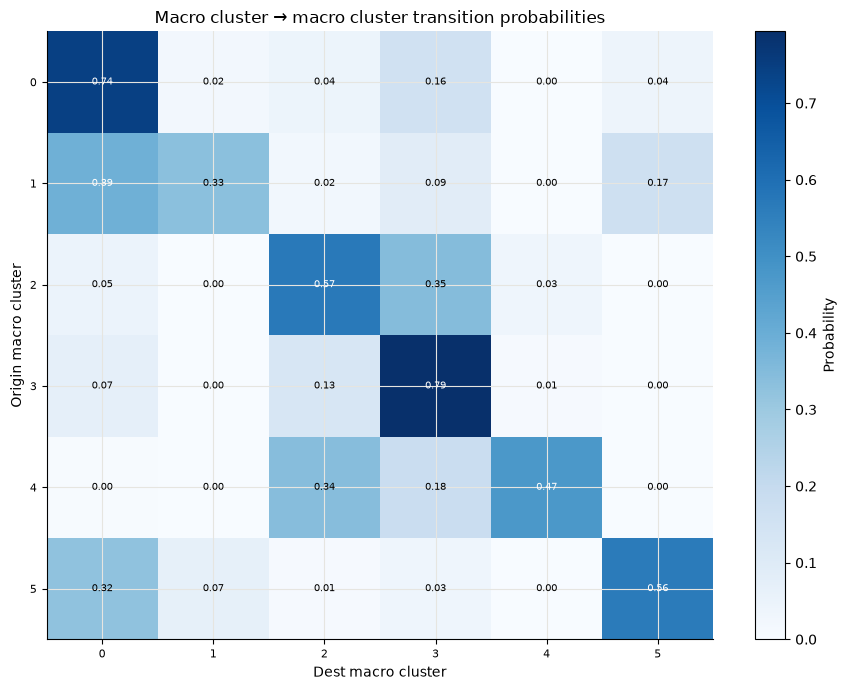

In [93]:
# Macro-to-macro transition probabilities
macro_trans = model.macro_transition_matrix()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(macro_trans.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(macro_trans.columns)))
ax.set_xticklabels(macro_trans.columns, fontsize=8)
ax.set_yticks(range(len(macro_trans.index)))
ax.set_yticklabels(macro_trans.index, fontsize=8)
ax.set_xlabel("Dest macro cluster")
ax.set_ylabel("Origin macro cluster")
ax.set_title("Macro cluster → macro cluster transition probabilities")
plt.colorbar(im, ax=ax, label="Probability")
for i in range(len(macro_trans.index)):
    for j in range(len(macro_trans.columns)):
        v = macro_trans.iloc[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7,
                color="white" if v > 0.35 else "black")
plt.tight_layout()
plt.show()

## 7. Micro-level results (within one macro cluster)

In [94]:
# ◆ Choose a macro cluster to drill into
INSPECT_MACRO = 0

msummary = model.micro_summary(INSPECT_MACRO)
if msummary is not None:
    print(f"=== Micro clusters inside macro cluster {INSPECT_MACRO} ===")
    display(msummary)
else:
    print(f"Macro cluster {INSPECT_MACRO} has no internal micro structure.")

=== Micro clusters inside macro cluster 0 ===


,n_stations,total_departures,internal_trips,outflow_trips,inflow_trips
cluster,,,,,
0.0,16,18951,6385,12566,12276
1.0,23,30337,9606,20731,20958
2.0,26,30546,10457,20089,21883
3.0,17,21328,9049,12279,13008
4.0,23,34260,9207,25053,24148
5.0,28,35486,13189,22297,23400
6.0,16,19105,5545,13560,13655
7.0,22,29748,10388,19360,16507
8.0,25,27600,7987,19613,18453


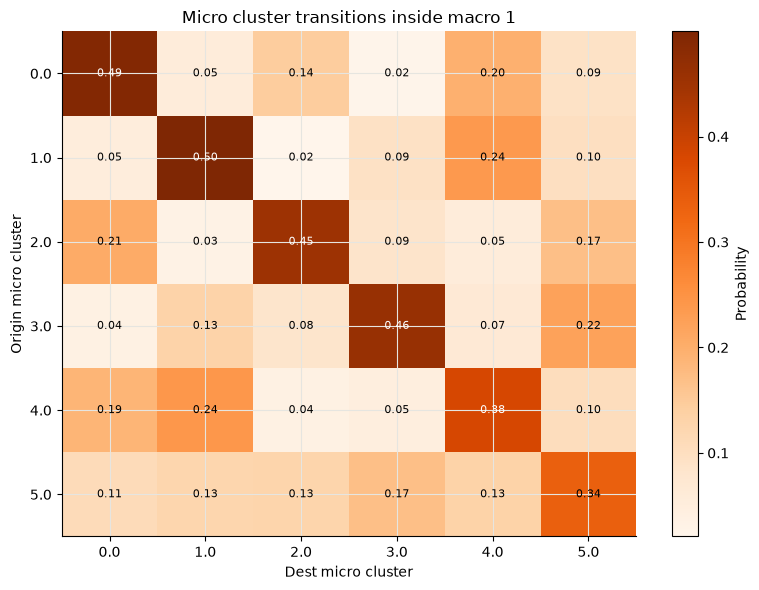

In [103]:
# Micro-to-micro transition matrix within the selected macro cluster
mt = model.micro_transition_matrix(INSPECT_MACRO)
if mt is not None:
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(mt.values, cmap="Oranges", aspect="auto")
    ax.set_xticks(range(len(mt.columns)))
    ax.set_xticklabels(mt.columns)
    ax.set_yticks(range(len(mt.index)))
    ax.set_yticklabels(mt.index)
    ax.set_xlabel("Dest micro cluster")
    ax.set_ylabel("Origin micro cluster")
    ax.set_title(f"Micro cluster transitions inside macro {INSPECT_MACRO}")
    plt.colorbar(im, ax=ax, label="Probability")
    for i in range(len(mt.index)):
        for j in range(len(mt.columns)):
            v = mt.iloc[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8,
                    color="white" if v > 0.35 else "black")
    plt.tight_layout()
    plt.show()

## 8. Hierarchical flow decomposition

In [96]:
# Full summary: every micro cluster with internal / sibling / external flows
full = model.full_summary()
full

n_stations  total_departures  internal  sibling_out  sibling_in  \
macro micro                                                                    
0     0.0            16             26316      6385        12566       12276   
      1.0            23             37085      9606        20731       20958   
      2.0            26             50869     10457        20089       21883   
      3.0            17             26284      9049        12279       13008   
      4.0            23             40708      9207        25053       24148   
      5.0            28             52787     13189        22297       23400   
      6.0            16             24348      5545        13560       13655   
      7.0            22             40998     10388        19360       16507   
      8.0            25             37334      7987        19613       18453   
      9.0            17             30555      9014        16820       18080   
1     0.0             1               683        16          306         258   
      1.0             1              1626        11          787         789   
      2.0             2              5243       179          849         956   
      3.0             1               264         3           52         104   
      4.0             2              3099        90          947        1167   
      5.0             2              2183        54          905         780   
      6.0             2              4774        84         1493        1162   
      7.0             2              1159        32          508         534   
      8.0             2              1301        39          520         548   
      9.0             2               622        29          112         181   
2     0.0            16             40276      9572        12885       11759   
      1.0            13             27172      3981        15513       15391   
      2.0            11             28194      6496         6101        5574   
      3.0            17             35815      4397        21482       23477   
      4.0            19             35952      5254        14805       15961   
      5.0            17             42081      6067        15520       16888   
      6.0            15             22489      2434        11677       10820   
      7.0            12             32985      7167         3007        3498   
      8.0             5              8444       906         3607        3717   
      9.0            14             46859      4953        26467       23979   
3     0.0            21             34767      9210        21385       23145   
      1.0            25             82246     18937        43013       41127   
      2.0            24             82913     17422        45967       51375   
      3.0            25             40371     12748        20123       20430   
      4.0            33            124293     24865        69215       68027   
      5.0            26            101527     19886        64197       60095   
      6.0            11             22907      3570        14383       14229   
      7.0            30             88811     23839        52723       54334   
      8.0            31             92166     26216        40148       37511   
      9.0            17             53273      9225        37021       37902   
4     0.0             4              3515       180         1470        1490   
      1.0             3              3427       319         1328        1252   
      2.0             2              2447        74         1093        1102   
      3.0             2              1652        85          955         930   
      4.0             4              4694       436         1737        1756   
      5.0             3              2329       144          688         770   
      6.0             3              3686       334          891         917   
      7.0             2              3154       201         1995        1959   
      8.0    

In [102]:
# ◆ Drill into one specific micro cluster
INSPECT_MACRO = 1
INSPECT_MICRO = 0

fc = model.micro_flows(INSPECT_MACRO, INSPECT_MICRO)
total = max(fc["total_departures"], 1)

print(f"=== Micro cluster ({INSPECT_MACRO}, {INSPECT_MICRO}) ===")
print(f"  Stations           : {fc['n_stations']}")
print(f"  Total departures   : {fc['total_departures']:>8,}")
print(f"  ├─ Internal        : {fc['internal_trips']:>8,}  ({fc['internal_trips']/total*100:5.1f}%)")
print(f"  ├─ Sibling outflow : {fc['sibling_out_trips']:>8,}  ({fc['sibling_out_trips']/total*100:5.1f}%)  (other micro, same macro)")
print(f"  └─ External outflow: {fc['external_out_trips']:>8,}  ({fc['external_out_trips']/total*100:5.1f}%)  (different macro)")
print(f"  Sibling inflow     : {fc['sibling_in_trips']:>8,}")
print(f"  External inflow    : {fc['external_in_trips']:>8,}")
print()
print("  External outflow by destination macro cluster:")
print(fc["ext_out_by_macro"].to_string(header=False))
print()
print("  External inflow by source macro cluster:")
print(fc["ext_in_by_macro"].to_string(header=False))

=== Micro cluster (1, 0) ===
  Stations           : 32
  Total departures   :   55,314
  ├─ Internal        :   16,055  ( 29.0%)
  ├─ Sibling outflow :   16,656  ( 30.1%)  (other micro, same macro)
  └─ External outflow:   22,603  ( 40.9%)  (different macro)
  Sibling inflow     :   15,464
  External inflow    :   18,141

  External outflow by destination macro cluster:
0     1450
2      215
3    17845
4     3093

  External inflow by source macro cluster:
0     1131
2      165
3    15117
4     1728


## 9. Visualisations

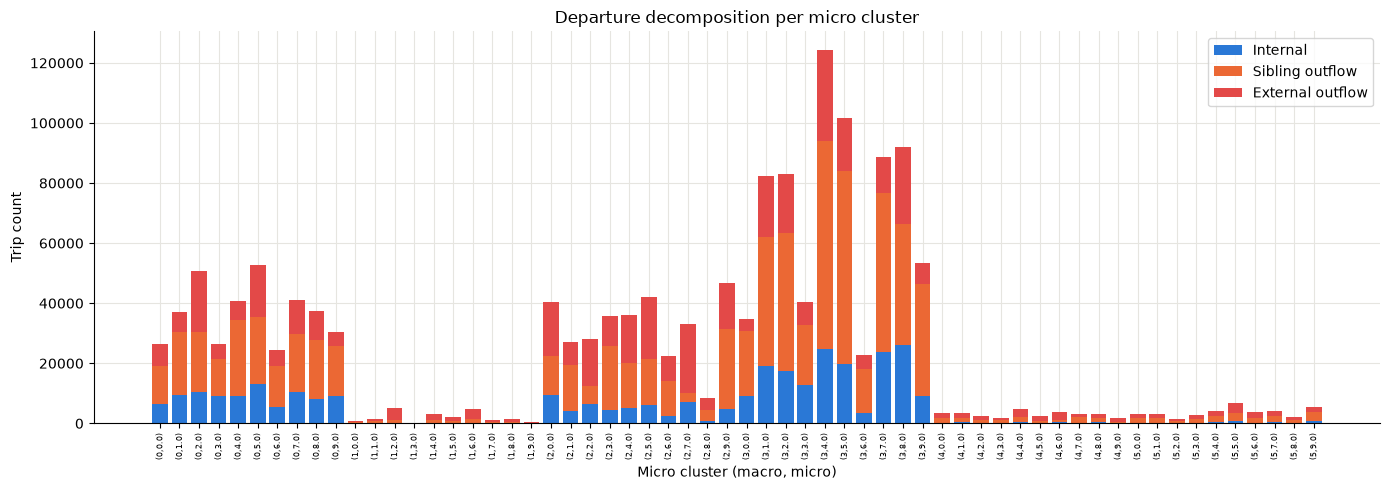

In [98]:
# ── 9a. Stacked bar: internal / sibling / external per micro cluster ──
full = model.full_summary()

fig, ax = plt.subplots(figsize=(14, 5))
labels = [f"({m},{s})" for m, s in full.index]
x = np.arange(len(labels))

ax.bar(x, full["internal"],      label="Internal",       color="#2a78d6")
ax.bar(x, full["sibling_out"],   bottom=full["internal"],
       label="Sibling outflow",  color="#eb6834")
ax.bar(x, full["external_out"],  bottom=full["internal"] + full["sibling_out"],
       label="External outflow", color="#e34948")

ax.set_xticks(x)
ax.set_xticklabels(labels, rotation=90, fontsize=6)
ax.set_xlabel("Micro cluster (macro, micro)")
ax.set_ylabel("Trip count")
ax.set_title("Departure decomposition per micro cluster")
ax.legend()
plt.tight_layout()
plt.show()

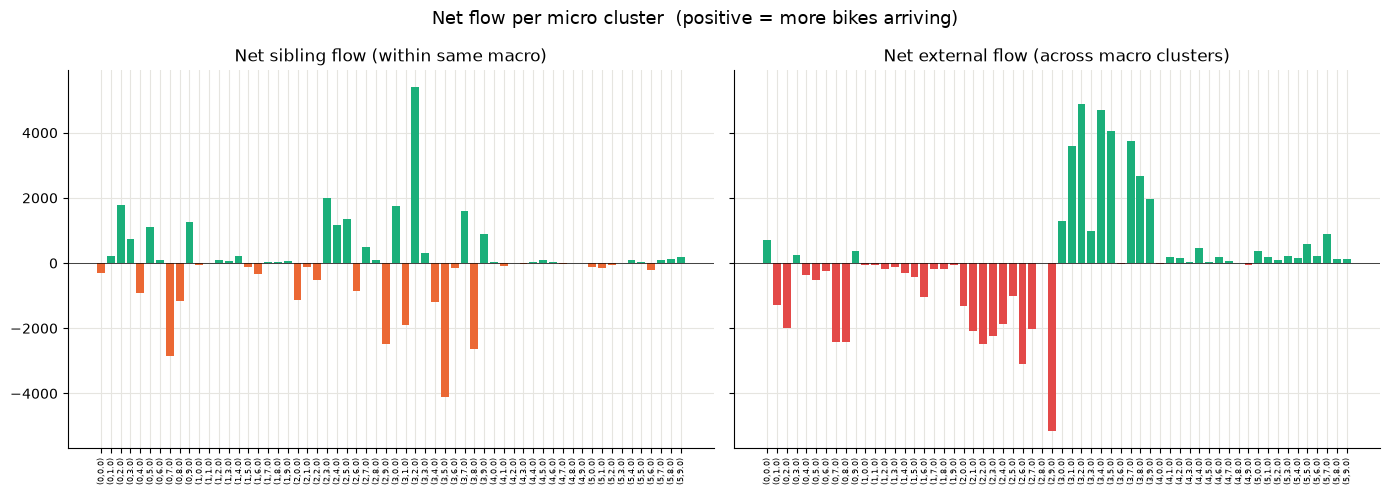

In [99]:
# ── 9b. Net flow bar chart per micro cluster ─────────────────────────
full = model.full_summary()
full["net_sibling"]  = full["sibling_in"]  - full["sibling_out"]
full["net_external"] = full["external_in"] - full["external_out"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
labels = [f"({m},{s})" for m, s in full.index]
x = np.arange(len(labels))

colors_sib = ["#1baf7a" if v >= 0 else "#eb6834" for v in full["net_sibling"]]
axes[0].bar(x, full["net_sibling"], color=colors_sib)
axes[0].set_title("Net sibling flow (within same macro)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(labels, rotation=90, fontsize=6)
axes[0].axhline(0, color="black", linewidth=0.5)

colors_ext = ["#1baf7a" if v >= 0 else "#e34948" for v in full["net_external"]]
axes[1].bar(x, full["net_external"], color=colors_ext)
axes[1].set_title("Net external flow (across macro clusters)")
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, rotation=90, fontsize=6)
axes[1].axhline(0, color="black", linewidth=0.5)

fig.suptitle("Net flow per micro cluster  (positive = more bikes arriving)", fontsize=13)
plt.tight_layout()
plt.show()

In [100]:
# ── 9c. Folium map coloured by macro, sized by micro ─────────────────
macro_cmap = plt.cm.tab10.colors
micro_cmap = plt.cm.Set3.colors

center = [stations["latitud"].mean(), stations["longitud"].mean()]
m = folium.Map(location=center, zoom_start=13, tiles="CartoDB positron")

for sid, row in stations.iterrows():
    M = int(row["macro"])
    s = int(row["micro"])
    # Border colour = macro cluster, fill colour = micro cluster
    border = to_hex(macro_cmap[M % len(macro_cmap)])
    fill   = to_hex(micro_cmap[s % len(micro_cmap)])
    folium.CircleMarker(
        location=[row["latitud"], row["longitud"]],
        radius=5,
        color=border,
        weight=2,
        fill=True,
        fill_color=fill,
        fill_opacity=0.85,
        popup=f"Station {sid}<br>Macro {M} · Micro {s}",
    ).add_to(m)

m

## 10. Quick-swap: rebuild with different settings

Change the macro/micro strategies and re-run from this cell.

In [101]:
# =====================================================================
# ◆  SWAP STRATEGIES HERE — then re-run this cell and the ones below  ◆
# =====================================================================

# Example: macro = K-Means k=5,  micro = K-Means k=6
NEW_MACRO_FN = lambda df: cluster_by_kmeans(df, k=5)
NEW_MICRO_K  = 6
NEW_MICRO_FN = lambda df: cluster_by_kmeans(df, k=min(NEW_MICRO_K, len(df)))

# =====================================================================

stations = build_hierarchy(stations, macro_fn=NEW_MACRO_FN, micro_fn=NEW_MICRO_FN)
model = HierarchicalMarkovModel(trips, stations)

print(f"Macro clusters: {stations['macro'].nunique()}")
print(f"Micro clusters total: {stations.groupby('macro')['micro'].nunique().sum()}")
model.full_summary()

Macro clusters: 5
Micro clusters total: 30


n_stations  total_departures  internal  sibling_out  sibling_in  \
macro micro                                                                    
0     0.0            16             34565      4015        19303       21108   
      1.0            27             97611     15331        16437       17261   
      2.0            10             25053      5859         6344        6061   
      3.0            25             54411      7451        20344       22621   
      4.0            25             67507     11552        34844       31376   
      5.0            17             25930      3068        13892       12737   
1     0.0            32             55314     16055        16656       15464   
      1.0            24             40272     14645        14660       15371   
      2.0            24             29384     10490        12735       11032   
      3.0            19             20858      8347         9744       11115   
      4.0            24             49557     11872        19078       19001   
      5.0            28             28120      8187        16137       17027   
2     0.0            15             45001      7598        12210       11433   
      1.0            15             17016      7966         5057        5084   
      2.0            13             14136      4000         6771        7546   
      3.0            14             36682     10788        10030       10066   
      4.0            11             22481      4643         5567        5110   
      5.0            12             21778      4294        10461       10857   
3     0.0            33             72688     19396        26670       26118   
      1.0            29             67578     17277        22909       24275   
      2.0            22             36116      6054        14838       13844   
      3.0            36            112880     31273        21910       23400   
      4.0            25             40062     11044        13234       13329   
      5.0            27             42011      9395        14359       12954   
4     0.0            29            113363     24091        42384       39690   
      1.0            27             48479     14315        23944       25086   
      2.0            25             91136     16463        31592       30579   
      3.0            28             71299     17722        32009       30590   
      4.0            26             90040     19859        36372       39880   
      5.0            19             27606      7738        10699       11175   

             external_out  external_in  
macro micro                             
0     0.0           11247         9362  
      1.0           65843        65566  
      2.0           12850        10443  
      3.0           26616        25033  
      4.0           21111        14688  
      5.0            8970         5949  
1     0.0           22603        18141  
      1.0           10967        11927  
      2.0            6159         4772  
      3.0            2767         3242  
      4.0           18607        18075  
      5.0            3796         3593  
2     0.0           25193        22881  
      1.0            3993         4325  
      2.0            3365         3507  
      3.0           15864        17728  
      4.0           12271        11205  
      5.0            7023         6565  
3     0.0           26622        24731  
      1.0           27392        27247  
      2.0           15224        14569  
      3.0           59697        59276  
      4.0           15784        17132  
      5.0           18257        16425  
4     0.0           46888        51470  
      1.0           10220        12384  
      2.0           43081        50649  
      3.0           21568        22979  
      4.0           33809        42965  
      5.0            9169        10127